# Medical appointment data: exploratory data analysis\n\nThis EDA uses the cleaned CSV. It documents quality, distributions, missingness, appointment outcomes, and calendar trends.\n

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 100)
df = pd.read_csv(Path('Medical_appointment_data_clean.csv'), parse_dates=['appointment_date_continuous'])
print(f'Shape: {df.shape[0]:,} rows x {df.shape[1]} columns')
display(df.head())


Shape: 109,557 rows x 26 columns


,specialty,appointment_time,gender,no_show,disability,place,appointment_shift,age,under_12,over_60,needs_companion,avg_temp,avg_rain,max_temp,max_rain,rainy_day_before,storm_day_before,rain_intensity,heat_intensity,appointment_date_continuous,hypertension,diabetes,alcoholism,handicap,scholarship,sms_received
0,psychotherapy,17,F,yes,intellectual,Lake Marvinville,afternoon,9.0,1.0,0.0,1,23.18,0.00,27.5,0.0,1,1,no_rain,warm,2020-01-01,0,0,0,0,0,0
1,NaN,7,M,no,intellectual,ITAPEMA,morning,11.0,1.0,0.0,1,14.31,0.02,16.5,0.6,1,1,no_rain,cold,2020-01-01,0,0,0,0,0,0
2,speech therapy,16,M,no,intellectual,ITAJAÍ,afternoon,8.0,1.0,0.0,1,21.61,0.01,29.9,0.2,1,1,no_rain,warm,2020-01-01,0,0,0,0,0,0
3,speech therapy,14,M,yes,intellectual,Sarahside,afternoon,9.0,1.0,0.0,1,21.39,0.11,24.1,1.4,1,1,moderate,mild,2020-01-01,0,0,0,0,0,1
4,physiotherapy,8,M,no,motor,ITAJAÍ,morning,NaN,NaN,NaN,0,20.15,0.02,23.1,0.2,1,1,no_rain,mild,2020-01-01,0,0,0,0,0,0


In [2]:
quality = pd.DataFrame({
    'missing_count': df.isna().sum(),
    'missing_pct': (df.isna().mean()*100).round(2),
    'unique_values': df.nunique(dropna=True)
}).sort_values('missing_pct', ascending=False)
display(df.dtypes.to_frame('dtype').T)
display(quality)
print('Exact duplicate rows:', df.duplicated().sum())
dates = df['appointment_date_continuous'].dropna()
print('Calendar range:', dates.min().date(), 'to', dates.max().date())
print('Missing calendar days:', len(pd.date_range(dates.min(), dates.max()).difference(dates.unique())))


,specialty,appointment_time,gender,no_show,disability,place,appointment_shift,age,under_12,over_60,needs_companion,avg_temp,avg_rain,max_temp,max_rain,rainy_day_before,storm_day_before,rain_intensity,heat_intensity,appointment_date_continuous,hypertension,diabetes,alcoholism,handicap,scholarship,sms_received
dtype,str,int64,str,str,str,str,str,float64,float64,float64,int64,float64,float64,float64,float64,int64,int64,str,str,datetime64[us],int64,int64,int64,int64,int64,int64


,missing_count,missing_pct,unique_values
over_60,22929,20.93,2
under_12,22929,20.93,2
age,22929,20.93,92
specialty,20100,18.35,8
disability,16990,15.51,2
place,11509,10.51,26289
max_rain,2243,2.05,326
avg_rain,2225,2.03,262
max_temp,2207,2.01,222
avg_temp,2191,2.00,1727


Exact duplicate rows: 0
Calendar range: 2020-01-01 to 2021-05-12
Missing calendar days: 0


,no_show,appointments,pct
0,no,74726,68.21
1,yes,34831,31.79


C:\Users\ABCD\AppData\Local\Temp\ipykernel_6468\3041057556.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='no_show', order=['no','yes'], ax=axes[0], palette=['#4C78A8','#E45756'])


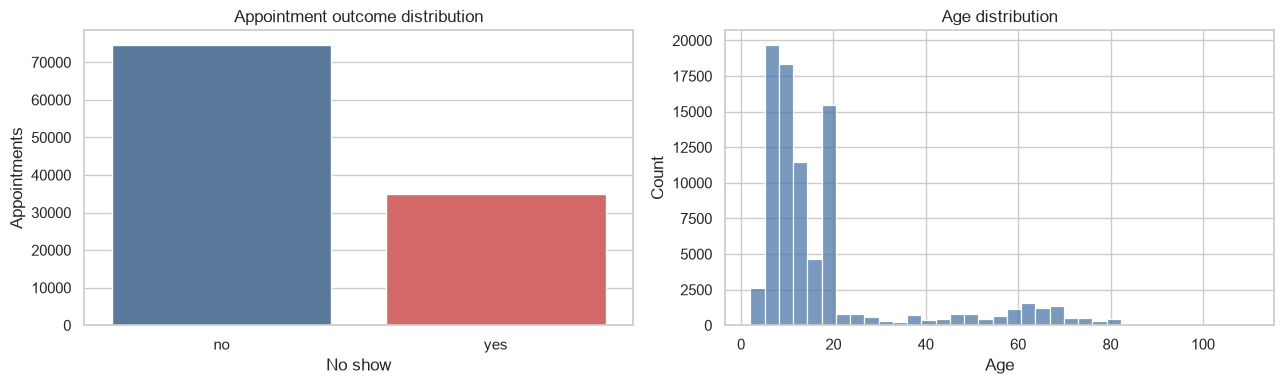

In [3]:
target = df['no_show'].value_counts().rename_axis('no_show').reset_index(name='appointments')
target['pct'] = (100 * target['appointments'] / len(df)).round(2)
display(target)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(data=df, x='no_show', order=['no','yes'], ax=axes[0], palette=['#4C78A8','#E45756'])
axes[0].set(title='Appointment outcome distribution', xlabel='No show', ylabel='Appointments')
sns.histplot(data=df, x='age', bins=35, ax=axes[1], color='#4C78A8')
axes[1].set(title='Age distribution', xlabel='Age')
plt.tight_layout(); plt.show()


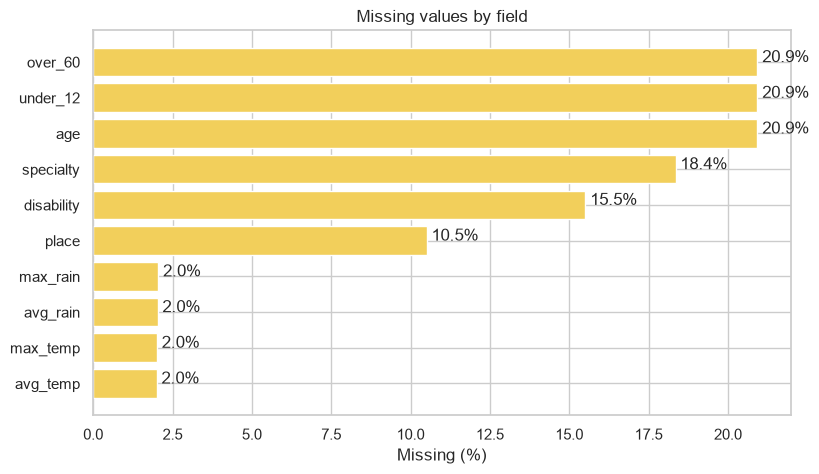

,gender,total,no_show_rate
0,M,82236,31.21
1,F,27074,33.69
2,I,247,17.41


,appointment_shift,total,no_show_rate
0,afternoon,59321,30.72
1,morning,50236,33.06


,specialty,total,no_show_rate
0,psychotherapy,28642,32.34
1,speech therapy,22321,27.93
2,physiotherapy,21001,34.37
3,NaN,20100,40.68
4,occupational therapy,11318,23.86
5,pedagogo,3535,15.98
6,enf,1681,19.75
7,assist,635,26.93
8,sem especialidade,324,52.78


,disability,total,no_show_rate
0,intellectual,62847,28.99
1,motor,29720,29.08
2,NaN,16990,46.91


,place,total,no_show_rate
0,ITAJAÍ,20512,8.88
1,NaN,11509,34.84
2,B. CAMBORIU,6018,9.19
3,CAMBORIU,5523,7.44
4,NAVEGANTES,3901,10.51
5,ITAPEMA,2665,9.68
6,BOMBINHAS,1707,11.72
7,PENHA,1038,6.17
8,PORTO BELO,950,11.68
9,BALN. PIÇARRAS,943,6.68


,under_12,total,no_show_rate
0,0.0,45964,34.41
1,1.0,40664,28.00
2,NaN,22929,33.28


,over_60,total,no_show_rate
0,0.0,80407,32.10
1,NaN,22929,33.28
2,1.0,6221,22.39


,needs_companion,total,no_show_rate
0,1,56966,28.97
1,0,52591,34.85


In [4]:
missing = quality.query('missing_count > 0').sort_values('missing_pct')
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(missing.index, missing['missing_pct'], color='#F2CF5B')
ax.set(title='Missing values by field', xlabel='Missing (%)', ylabel='')
for i, value in enumerate(missing['missing_pct']):
    ax.text(value + .15, i, f'{value:.1f}%')
plt.show()

def no_show_by(column, top_n=12):
    result = (df.groupby(column, dropna=False)['no_show'].agg(total='size', no_show_rate=lambda x: x.eq('yes').mean())
              .sort_values('total', ascending=False).head(top_n).reset_index())
    result['no_show_rate'] = (result['no_show_rate'] * 100).round(2)
    return result

for field in ['gender','appointment_shift','specialty','disability','place','under_12','over_60','needs_companion']:
    display(no_show_by(field))


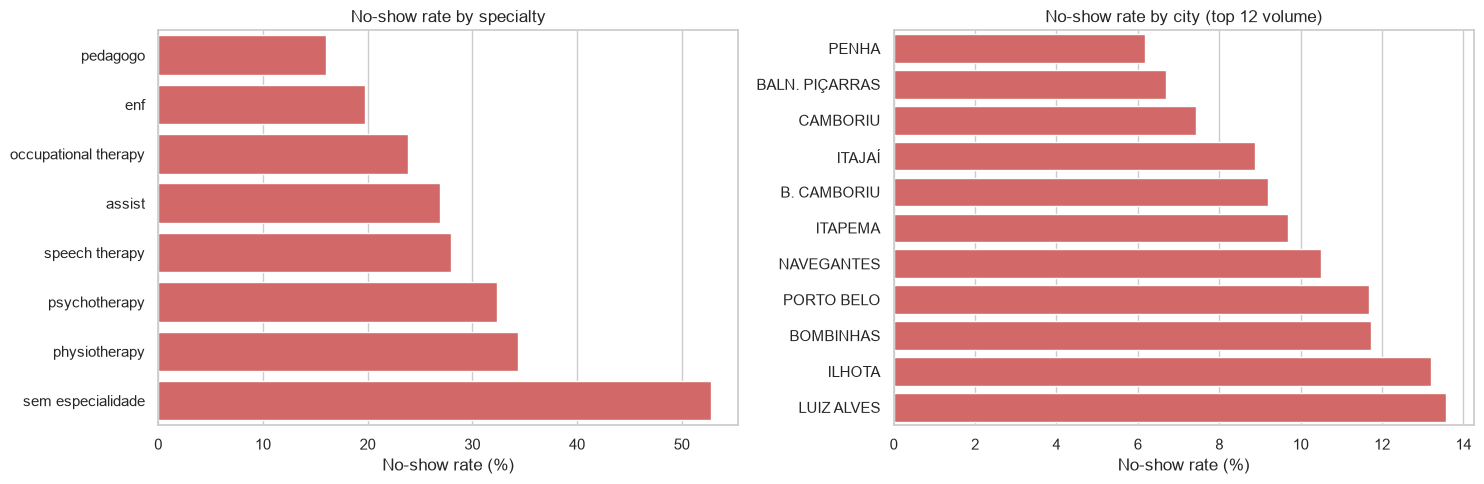

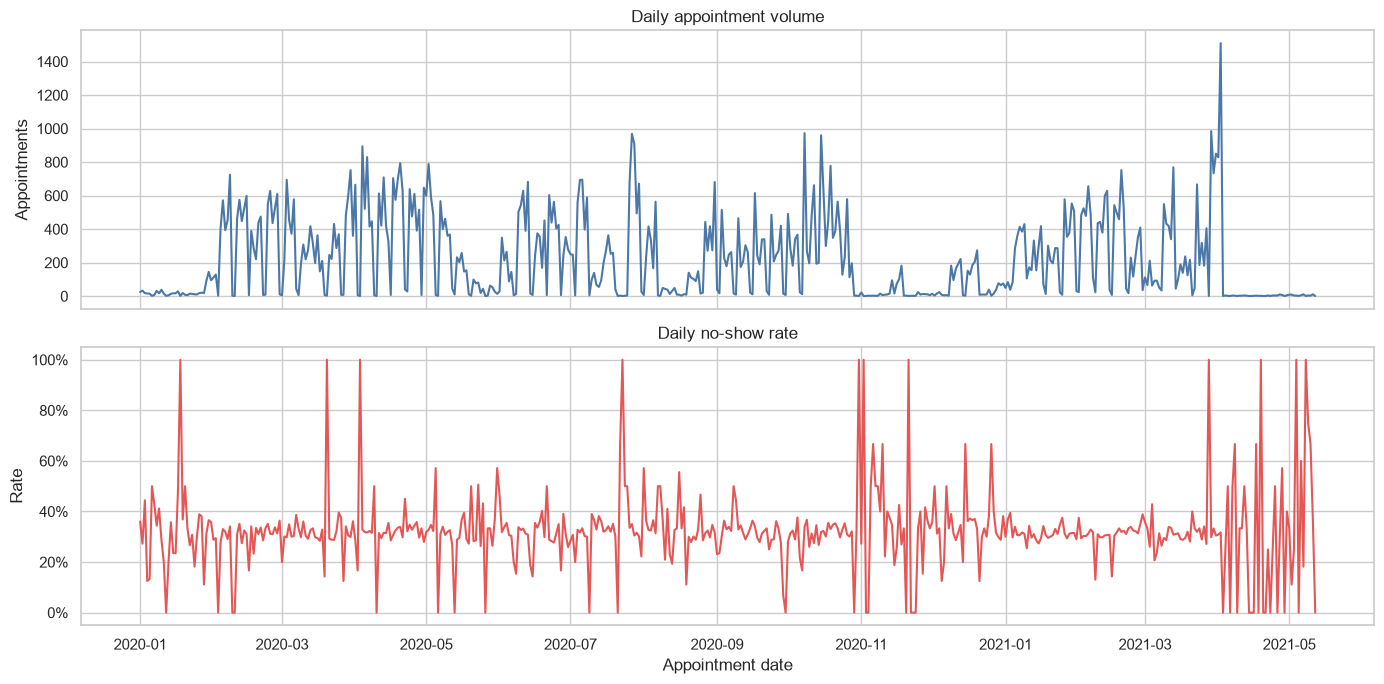

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, field, title in zip(axes, ['specialty','place'], ['No-show rate by specialty', 'No-show rate by city (top 12 volume)']):
    rates = no_show_by(field).sort_values('no_show_rate')
    sns.barplot(data=rates, x='no_show_rate', y=field, ax=ax, color='#E45756')
    ax.set(title=title, xlabel='No-show rate (%)', ylabel='')
plt.tight_layout(); plt.show()

daily = (df.assign(no_show_flag=df['no_show'].eq('yes')).groupby('appointment_date_continuous')
         .agg(appointments=('no_show','size'), no_show_rate=('no_show_flag','mean')).reset_index())
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
sns.lineplot(data=daily, x='appointment_date_continuous', y='appointments', ax=axes[0], color='#4C78A8')
sns.lineplot(data=daily, x='appointment_date_continuous', y='no_show_rate', ax=axes[1], color='#E45756')
axes[0].set(title='Daily appointment volume', xlabel='', ylabel='Appointments')
axes[1].set(title='Daily no-show rate', xlabel='Appointment date', ylabel='Rate')
axes[1].yaxis.set_major_formatter(lambda x, pos: f'{x:.0%}')
plt.tight_layout(); plt.show()


## Interpretation note\n\nThe charts are descriptive, not causal. Preserve missingness in later modeling and ensure all predictor values are known before the appointment.\n